# MultiCoNER 2 data analytics

This notebook explores the local MultiCoNER 2 CoNLL files without changing the source data. It streams one sentence at a time, so even the large test splits are not loaded as token-level dataframes.

Expected layout: `dataset/multiconer2023/<language-folder>/*_{train,dev,test}.conll`. Run from this workspace or update `DATA_ROOT` below.

## 1. Imports and dataset location

The parser accepts metadata headers such as `# id ... domain=en`, four-column CoNLL token rows, and blank-line sentence boundaries. Missing or malformed rows are counted and reported.

In [9]:
from collections import Counter, defaultdict
from pathlib import Path
import re

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import HTML, display

plt.style.use('seaborn-v0_8-whitegrid')


def display_table(rows, columns=None, title=None):
    """Build and display an analysis table as a pandas DataFrame."""
    frame = pd.DataFrame(rows, columns=columns)
    if title:
        display(HTML(f'<h4>{title}</h4>'))
    display(frame)
    return frame


def display_grouped_bars(rows, value_key, title):
    """Plot split-wise values as a grouped pandas bar chart."""
    frame = pd.DataFrame(rows)
    table = frame.pivot(index='language', columns='split', values=value_key).fillna(0)
    table = table.reindex(columns=[s for s in ('train', 'dev', 'test') if s in table.columns])
    ax = table.plot(kind='bar', figsize=(13, 5), width=0.8)
    ax.set_title(title)
    ax.set_xlabel('Language folder')
    ax.set_ylabel(value_key.replace('_', ' ').capitalize())
    ax.tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.show()


def find_dataset_root(start: Path) -> Path:
    """Find multiconer2023 by walking up from the notebook kernel directory."""
    for parent in (start, *start.parents):
        for candidate in (parent / 'dataset' / 'multiconer2023', parent / 'multiconer2023'):
            if candidate.is_dir() and any(candidate.glob('*/*.conll')):
                return candidate
    raise FileNotFoundError(
        'Could not find dataset/multiconer2023 containing language folders and .conll files. '
        'Start Jupyter from the workspace root or set DATA_ROOT to the dataset directory.'
    )


DATA_ROOT = find_dataset_root(Path.cwd())
print(f'Dataset: {DATA_ROOT}')
print(f'Language folders: {sum(1 for p in DATA_ROOT.iterdir() if p.is_dir())}')

Dataset: c:\Users\offic\Documents\Projects\MultiCoNER\dataset\multiconer2023
Language folders: 13


## 2. Streaming CoNLL parser and aggregate statistics

A `B-...` tag starts an entity span. An `I-...` tag is checked against the preceding entity type; invalid continuations are counted as warnings, while parsing continues. Token tags and entity starts are counted separately.

In [10]:
META_RE = re.compile(r'\b(domain|corrupt)=([^\s]+)')
TAG_RE = re.compile(r'^(?:O|[BI]-.+)$')

def _new_stats():
    return {
        'documents': 0, 'tokens': 0, 'length_sum': 0,
        'length_hist': Counter(), 'malformed_rows': 0,
        'invalid_i_tags': 0, 'metadata_headers': 0,
        'corrupt_true': 0, 'corrupt_false': 0,
        'domain_counts': Counter(),
    }

def analyze_file(path: Path, language: str, split: str, stats_by_group,
                 tag_counts, entity_counts, domain_stats):
    """Stream one CoNLL file and update aggregate counters in place."""
    group_key = (language, split)
    stats = stats_by_group[group_key]
    doc = {'tokens': 0, 'prev_type': None, 'domain': None, 'corrupt': None}

    def finish_sentence():
        if doc['tokens'] == 0:
            return
        stats['documents'] += 1
        stats['tokens'] += doc['tokens']
        stats['length_sum'] += doc['tokens']
        stats['length_hist'][doc['tokens']] += 1
        if doc['corrupt'] is True:
            stats['corrupt_true'] += 1
        elif doc['corrupt'] is False:
            stats['corrupt_false'] += 1
        if doc['domain']:
            stats['domain_counts'][doc['domain']] += 1
            d_stats = domain_stats[(language, split, doc['domain'])]
            d_stats['documents'] += 1
            d_stats['tokens'] += doc['tokens']
        doc.update(tokens=0, prev_type=None, domain=None, corrupt=None)

    with path.open('r', encoding='utf-8-sig', errors='replace') as stream:
        for line in stream:
            line = line.strip()
            if not line:
                finish_sentence()
                continue
            if line.startswith('#'):
                if doc['tokens']:
                    finish_sentence()
                fields = dict(META_RE.findall(line))
                if fields:
                    stats['metadata_headers'] += 1
                    doc['domain'] = fields.get('domain')
                    corrupt_value = fields.get('corrupt', '').lower()
                    if corrupt_value in {'true', 'false'}:
                        doc['corrupt'] = corrupt_value == 'true'
                continue

            columns = line.split()
            if len(columns) != 4 or not TAG_RE.fullmatch(columns[-1]):
                stats['malformed_rows'] += 1
                doc['prev_type'] = None
                continue

            tag = columns[-1]
            doc['tokens'] += 1
            tag_counts[(language, split, tag)] += 1
            if tag == 'O':
                doc['prev_type'] = None
            elif tag.startswith('B-'):
                entity_type = tag[2:]
                entity_counts[(language, split, entity_type)] += 1
                doc['prev_type'] = entity_type
            else:
                entity_type = tag[2:]
                if doc['prev_type'] != entity_type:
                    stats['invalid_i_tags'] += 1
                doc['prev_type'] = entity_type
    finish_sentence()

stats_by_group = defaultdict(_new_stats)
tag_counts = Counter()
entity_counts = Counter()
domain_stats = defaultdict(lambda: {'documents': 0, 'tokens': 0})
files = sorted(DATA_ROOT.glob('*/*.conll'))
if not files:
    raise FileNotFoundError(f'No .conll files found under {DATA_ROOT}')

for file_path in files:
    match = re.search(r'_(train|dev|test)\.conll$', file_path.name, flags=re.IGNORECASE)
    if not match:
        continue
    split = match.group(1).lower()
    analyze_file(file_path, file_path.parent.name, split,
                 stats_by_group, tag_counts, entity_counts, domain_stats)

print(f'Analyzed {len(files)} CoNLL files.')
if not stats_by_group:
    raise ValueError(f'No files with recognized train/dev/test names found under {DATA_ROOT}')

Analyzed 39 CoNLL files.


## 3. Dataset overview

Sentence-length statistics are computed from a compact length histogram, not from a token-level table.

In [11]:
def histogram_quantile(histogram, q):
    total = sum(histogram.values())
    if total == 0:
        return float('nan')
    target = max(1, int((total - 1) * q) + 1)
    cumulative = 0
    for length, count in sorted(histogram.items()):
        cumulative += count
        if cumulative >= target:
            return length


overview_rows = []
for (language, split), stats in sorted(stats_by_group.items()):
    docs = stats['documents']
    overview_rows.append({
        'language': language, 'split': split, 'documents': docs,
        'tokens': stats['tokens'],
        'mean_tokens_per_document': stats['length_sum'] / docs if docs else 0,
        'median_tokens_per_document': histogram_quantile(stats['length_hist'], 0.5),
        'p95_tokens_per_document': histogram_quantile(stats['length_hist'], 0.95),
        'entity_spans': sum(n for (lang, sp, _), n in entity_counts.items()
                            if lang == language and sp == split),
        'malformed_rows': stats['malformed_rows'],
        'invalid_i_tags': stats['invalid_i_tags'],
    })

overview = pd.DataFrame(overview_rows).sort_values(['language', 'split']).reset_index(drop=True)
display(overview)
print(f"Total documents: {overview['documents'].sum():,} | "
      f"tokens: {overview['tokens'].sum():,} | "
      f"entity spans: {overview['entity_spans'].sum():,}")

,language,split,documents,tokens,mean_tokens_per_document,median_tokens_per_document,p95_tokens_per_document,entity_spans,malformed_rows,invalid_i_tags
0,BN-Bangla,dev,507,6772,13.357002,12,23,676,0,0
1,BN-Bangla,test,19859,256556,12.918878,12,22,25013,0,0
2,BN-Bangla,train,9708,130181,13.409662,13,22,13223,0,0
3,DE-German,dev,512,7502,14.652344,14,23,841,0,0
4,DE-German,test,20145,292718,14.530553,14,24,28877,0,0
5,DE-German,train,9785,148310,15.156873,15,25,15951,0,0
6,EN-English,dev,871,13323,15.296211,15,25,1296,0,0
7,EN-English,test,249980,3773671,15.095892,14,25,377805,0,0
8,EN-English,train,16778,253011,15.079926,14,25,25449,0,0
9,ES-Spanish,dev,854,13462,15.763466,16,25,1231,0,0


Total documents: 2,709,465 | tokens: 41,173,752 | entity spans: 4,023,223


## 4. Compare languages and splits

These side-by-side plots help reveal differences in split size and annotation volume.

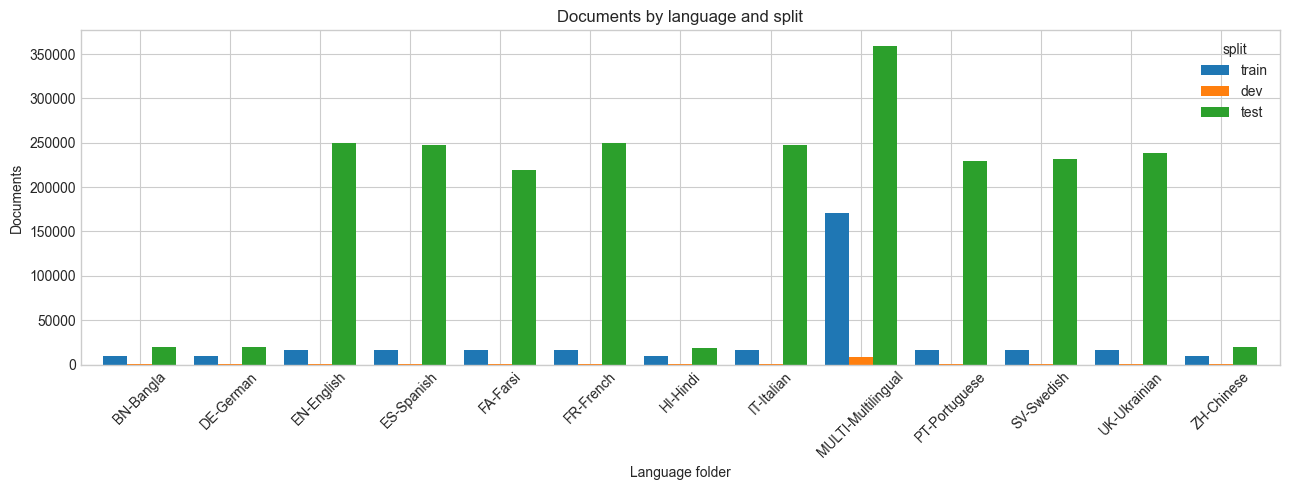

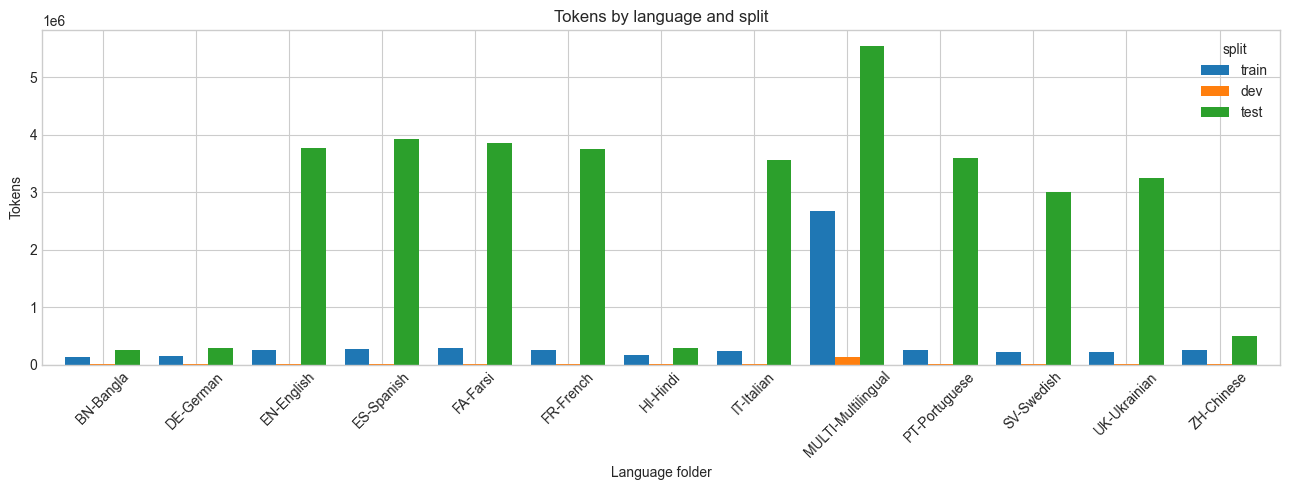

In [12]:
display_grouped_bars(overview, 'documents', 'Documents by language and split')
display_grouped_bars(overview, 'tokens', 'Tokens by language and split')

## 5. Entity and token-label distributions

The entity table counts `B-` span starts by fine-grained type. The token table also includes `O` and `I-` tags.

,entity_type,count
0,HumanSettlement,594033
1,Artist,555501
2,OtherPER,243098
3,Athlete,242606
4,VisualWork,233168
5,ORG,213635
6,Politician,197651
7,WrittenWork,197093
8,Facility,162133
9,MusicalWork,133591


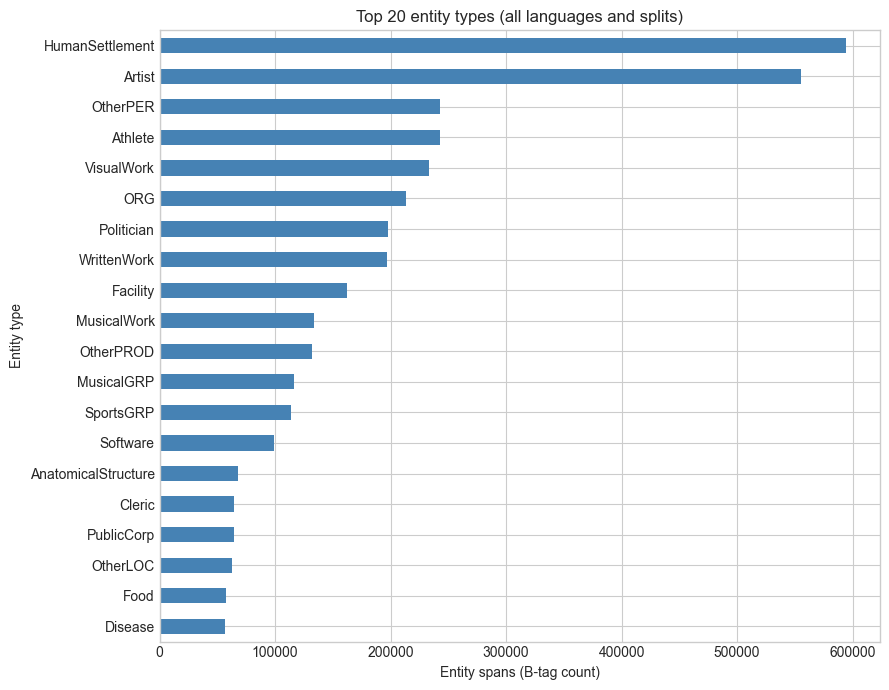

,tag,count
0,O,33080579
1,I-Artist,623847
2,B-HumanSettlement,594033
3,B-Artist,555501
4,I-VisualWork,435991
...,...,...
62,I-Drink,7851
63,I-Symptom,7028
64,I-PrivateCorp,6494
65,B-PrivateCorp,6453


In [13]:
entity_rows = [
    {'language': language, 'split': split, 'entity_type': entity_type, 'count': count}
    for (language, split, entity_type), count in entity_counts.items()
]
entity_distribution = pd.DataFrame(entity_rows)
if entity_distribution.empty:
    print('No B- entity tags were found.')
else:
    top_entities = (entity_distribution.groupby('entity_type', as_index=False)['count'].sum()
                    .sort_values('count', ascending=False))
    display(top_entities.head(25).reset_index(drop=True))

    ax = (top_entities.head(20).sort_values('count')
          .plot(x='entity_type', y='count', kind='barh', legend=False,
                figsize=(9, 7), color='steelblue'))
    ax.set_title('Top 20 entity types (all languages and splits)')
    ax.set_xlabel('Entity spans (B-tag count)')
    ax.set_ylabel('Entity type')
    plt.tight_layout()
    plt.show()

tag_rows = [
    {'language': language, 'split': split, 'tag': tag, 'count': count}
    for (language, split, tag), count in tag_counts.items()
]
tag_distribution = pd.DataFrame(tag_rows)
display(tag_distribution.groupby('tag', as_index=False)['count'].sum()
        .sort_values('count', ascending=False).reset_index(drop=True))

## 6. Sentence-length distributions

The table bins sentence lengths in 10-token ranges and pools counts by split. Binning keeps the display compact while preserving the complete underlying histograms in memory.

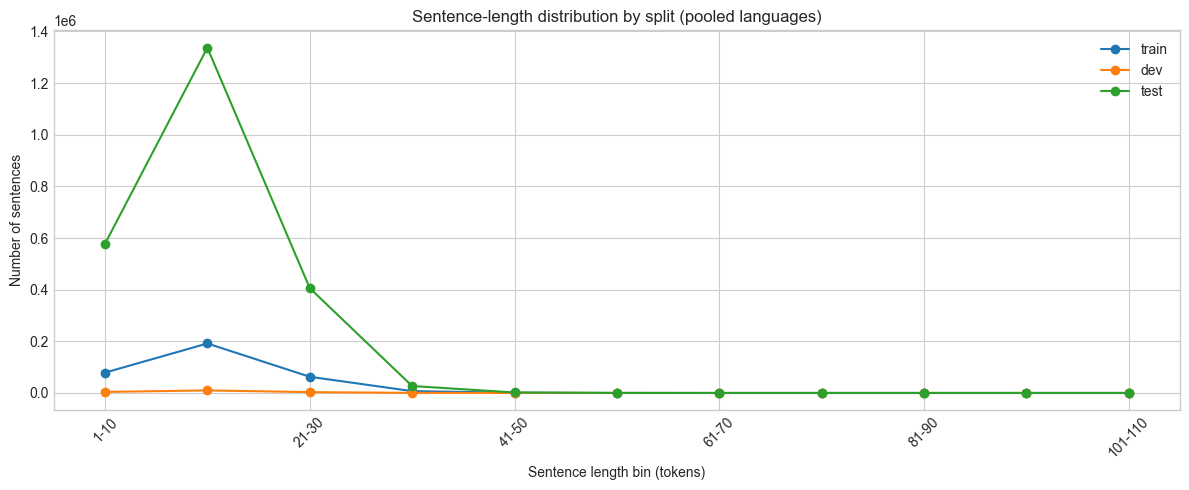

,train,dev,test
length_bin,,,
1-10,78874,4092,577664
11-20,191712,9950,1337310
21-30,62826,3292,405969
31-40,7142,408,26918
41-50,1014,44,1972
51-60,60,4,153
61-70,14,0,24
71-80,2,0,7
81-90,0,0,2


In [14]:
split_histograms = defaultdict(Counter)
for (language, split), stats in stats_by_group.items():
    split_histograms[split].update(stats['length_hist'])

length_bins = defaultdict(Counter)
for split, histogram in split_histograms.items():
    for length, count in histogram.items():
        lower = ((length - 1) // 10) * 10 + 1
        length_bins[split][f'{lower}-{lower + 9}'] += count
bin_order = sorted({label for histogram in length_bins.values() for label in histogram},
                   key=lambda label: int(label.split('-')[0]))
length_rows = [{'length_bin': label, **{split: length_bins[split][label]
                                        for split in ('train', 'dev', 'test')}}
               for label in bin_order]
length_frame = pd.DataFrame(length_rows).fillna(0).set_index('length_bin')
ax = length_frame.plot(figsize=(12, 5), marker='o', linewidth=1.5)
ax.set_title('Sentence-length distribution by split (pooled languages)')
ax.set_xlabel('Sentence length bin (tokens)')
ax.set_ylabel('Number of sentences')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()
display(length_frame)

## 7. Multilingual domain and noise metadata checks

For `MULTI-Multilingual`, the `domain=` metadata field identifies the instance language. Noise coverage is only measurable where a header explicitly includes `corrupt=True` or `corrupt=False`; absence of that field is not treated as a clean example.

In [15]:
multilingual_rows = []
for (language, split, domain), values in sorted(domain_stats.items()):
    if language == 'MULTI-Multilingual':
        multilingual_rows.append({
            'split': split, 'domain': domain,
            'documents': values['documents'], 'tokens': values['tokens'],
        })
if not multilingual_rows:
    print('No domain metadata was found for MULTI-Multilingual.')
else:
    multilingual_rows.sort(key=lambda row: (row['split'], row['domain']))
    display_table(multilingual_rows, ['split', 'domain', 'documents', 'tokens'],
                  'Multilingual set by metadata domain')

noise_rows = []
for (language, split), stats in sorted(stats_by_group.items()):
    noise_rows.append({
        'language': language, 'split': split,
        'metadata_headers': stats['metadata_headers'],
        'corrupt_true': stats['corrupt_true'],
        'corrupt_false': stats['corrupt_false'],
        'corrupt_status_missing_or_unrecognized': max(
            0, stats['metadata_headers'] - stats['corrupt_true'] - stats['corrupt_false']),
    })
noise_rows = [row for row in noise_rows if row['corrupt_true'] + row['corrupt_false'] > 0]
display_table(noise_rows, ['language', 'split', 'metadata_headers', 'corrupt_true',
                           'corrupt_false', 'corrupt_status_missing_or_unrecognized'],
              'Splits with explicit corrupt metadata')
print('If the displayed noise table is empty, these files do not encode corrupt=... in their headers.')

,split,domain,documents,tokens
0,dev,bn,507,6772
1,dev,de,512,7502
2,dev,en,871,13323
3,dev,es,854,13462
4,dev,fa,855,15850
5,dev,fr,857,13062
6,dev,hi,514,8639
7,dev,it,858,12336
8,dev,pt,854,13237
9,dev,sv,856,11286


,language,split,metadata_headers,corrupt_true,corrupt_false,corrupt_status_missing_or_unrecognized
0,DE-German,test,19622,5880,5,13737
1,EN-English,test,249980,74960,34,174986
2,ES-Spanish,test,246900,74050,20,172830
3,FR-French,test,249786,74918,18,174850
4,IT-Italian,test,247881,74334,29,173518
5,MULTI-Multilingual,test,357668,74524,279,282865
6,PT-Portuguese,test,229480,68822,36,160622
7,SV-Swedish,test,231190,69342,14,161834
8,ZH-Chinese,test,19790,5696,240,13854


If the displayed noise table is empty, these files do not encode corrupt=... in their headers.


## 8. Top labels per language and data-quality checks

Use these tables to compare annotation mix and to locate files that may need closer inspection.

In [16]:
if not entity_counts:
    print('No B- entity tags were found.')
else:
    entity_distribution = pd.DataFrame([
        {'language': language, 'entity_type': entity_type, 'count': count}
        for (language, split, entity_type), count in entity_counts.items()
    ])
    language_totals = (entity_distribution.groupby(['language', 'entity_type'], as_index=False)['count']
                       .sum())
    top_per_language = (language_totals.sort_values(['language', 'count'], ascending=[True, False])
                        .groupby('language', as_index=False).head(5).reset_index(drop=True))
    display(top_per_language)

quality = overview.loc[(overview['malformed_rows'] > 0) | (overview['invalid_i_tags'] > 0),
                       ['language', 'split', 'malformed_rows', 'invalid_i_tags']]
if quality.empty:
    print('No malformed token rows or unmatched I- tags were detected.')
else:
    print('Files with parse/IOB warnings (investigate before drawing conclusions):')
    display(quality.reset_index(drop=True))

split_totals = (overview.groupby('split', as_index=False)[
    ['documents', 'tokens', 'entity_spans', 'malformed_rows', 'invalid_i_tags']
].sum().sort_values('split').reset_index(drop=True))
display(split_totals)

,language,entity_type,count
0,BN-Bangla,HumanSettlement,7670
1,BN-Bangla,Artist,3982
2,BN-Bangla,ORG,2686
3,BN-Bangla,Politician,1964
4,BN-Bangla,OtherPER,1826
...,...,...,...
60,ZH-Chinese,HumanSettlement,5654
61,ZH-Chinese,Artist,5443
62,ZH-Chinese,ORG,2793
63,ZH-Chinese,Athlete,2696


Files with parse/IOB warnings (investigate before drawing conclusions):


,language,split,malformed_rows,invalid_i_tags
0,ES-Spanish,test,0,1
1,FR-French,test,0,2
2,MULTI-Multilingual,test,0,1
3,PT-Portuguese,test,0,1


,split,documents,tokens,entity_spans,malformed_rows,invalid_i_tags
0,dev,17790,279646,26610,0,0
1,test,2350027,35549126,3486775,0,5
2,train,341648,5344980,509838,0,0


## 9. Questions to guide interpretation

- Which language/split pairs have the greatest change in token or document volume?
- Are the fine-grained entity types similarly represented across languages, or are some types especially sparse?
- Do sentence lengths or entity rates vary noticeably by split?
- Does the multilingual set have a balanced distribution of `domain` values?
- Are any malformed rows or unmatched `I-` tags concentrated in particular files?

Counts are descriptive, not model-quality measurements. Test-set annotations and metadata can differ from train/dev availability; verify the dataset documentation before comparing splits.

## 10. Additional analyses

The following cells append six further analyses without modifying the existing cells above. All use the same streaming parser style (one sentence at a time) so they scale to the full 41M-token test split.



### 1. Entity span length & multi-token stats


,language,split,total_spans,mean_span_length,pct_single_token,pct_multi_token,max_span_length
0,BN-Bangla,dev,676,1.910,37.7,62.3,8
1,BN-Bangla,test,25013,1.883,39.7,60.3,11
2,BN-Bangla,train,13223,1.879,38.6,61.4,9
3,DE-German,dev,841,2.121,32.3,67.7,21
4,DE-German,test,28877,2.162,29.5,70.5,21
5,DE-German,train,15951,2.111,32.6,67.4,24
6,EN-English,dev,1296,2.124,27.8,72.2,10
7,EN-English,test,377805,2.129,28.7,71.3,20
8,EN-English,train,25449,2.123,28.8,71.2,15
9,ES-Spanish,dev,1231,2.064,34.4,65.6,9


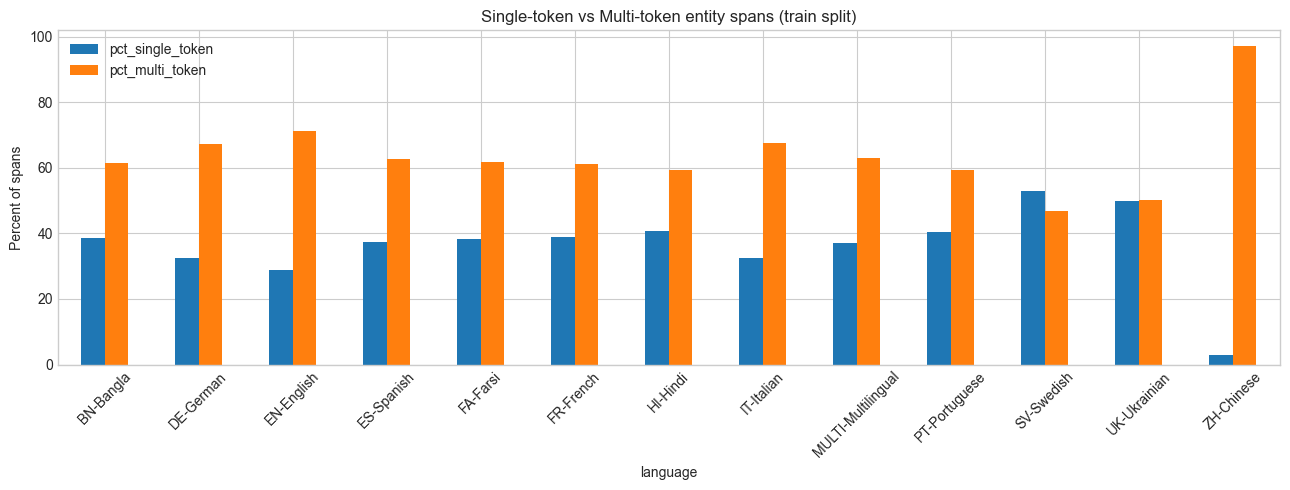

,span_length,count,pct
0,1,189014,37.073345
1,2,200758,39.376822
2,3,64278,12.607534
3,4,25658,5.032579
4,5,12054,2.364280
5,6,7694,1.509107
6,7,4528,0.888125
7,8,2624,0.514673
8,9,1260,0.247137
9,10,782,0.153382


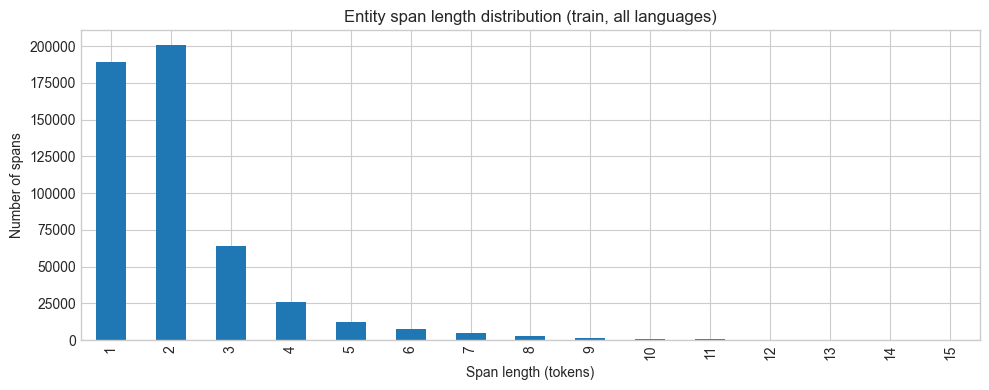

In [17]:
from collections import defaultdict, Counter
import re

TAG_RE = re.compile(r'^(?:O|[BI]-.+)$')

def _new_span_stats():
    return {'span_lengths': Counter(), 'spans_by_type': Counter(),
            'span_lengths_by_type': defaultdict(Counter),
            'single_token_spans': 0, 'multi_token_spans': 0,
            'total_spans': 0, 'total_tokens_in_spans': 0}

span_stats_by_group = defaultdict(_new_span_stats)

def analyze_spans_file(path, language, split, stats_container):
    group_key = (language, split)
    stats = stats_container[group_key]
    open_span = None  # (entity_type, length)

    def close_span():
        nonlocal open_span
        if open_span is not None:
            etype, length = open_span
            stats['span_lengths'][length] += 1
            stats['spans_by_type'][etype] += 1
            stats['span_lengths_by_type'][etype][length] += 1
            stats['total_spans'] += 1
            stats['total_tokens_in_spans'] += length
            if length == 1:
                stats['single_token_spans'] += 1
            else:
                stats['multi_token_spans'] += 1
            open_span = None

    with path.open('r', encoding='utf-8-sig', errors='replace') as stream:
        for line in stream:
            line = line.strip()
            if not line:
                close_span()
                continue
            if line.startswith('#'):
                continue
            columns = line.split()
            if len(columns) != 4 or not TAG_RE.fullmatch(columns[-1]):
                close_span()
                continue
            tag = columns[-1]
            if tag == 'O':
                close_span()
            elif tag.startswith('B-'):
                close_span()
                open_span = (tag[2:], 1)
            else:  # I-X
                etype = tag[2:]
                if open_span is not None and open_span[0] == etype:
                    open_span = (etype, open_span[1] + 1)
                else:  # mismatched or orphan I-tag
                    close_span()
                    open_span = (etype, 1)
        close_span()

files = sorted(DATA_ROOT.glob('*/*.conll'))
for file_path in files:
    match = re.search(r'_(train|dev|test)\.conll$', file_path.name, flags=re.IGNORECASE)
    if not match:
        continue
    split = match.group(1).lower()
    analyze_spans_file(file_path, file_path.parent.name, split, span_stats_by_group)

rows = []
for (language, split), stats in sorted(span_stats_by_group.items()):
    total = stats['total_spans']
    if total == 0:
        continue
    mean_len = stats['total_tokens_in_spans'] / total
    rows.append({
        'language': language, 'split': split,
        'total_spans': total,
        'mean_span_length': round(mean_len, 3),
        'pct_single_token': round(100 * stats['single_token_spans'] / total, 1),
        'pct_multi_token': round(100 * stats['multi_token_spans'] / total, 1),
        'max_span_length': max(stats['span_lengths']) if stats['span_lengths'] else 0,
    })

span_summary = pd.DataFrame(rows)
display(span_summary)

# Plot: single vs multi token share on train
train_rows = span_summary[span_summary['split'] == 'train']
if not train_rows.empty:
    ax = train_rows.plot(x='language', y=['pct_single_token', 'pct_multi_token'],
                         kind='bar', figsize=(13, 5))
    ax.set_title('Single-token vs Multi-token entity spans (train split)')
    ax.set_ylabel('Percent of spans')
    ax.tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.show()

# Span length distribution pooled across languages on train
all_lengths = Counter()
for (lang, split), stats in span_stats_by_group.items():
    if split == 'train':
        all_lengths.update(stats['span_lengths'])
length_df = pd.DataFrame(sorted(all_lengths.items()), columns=['span_length', 'count'])
length_df['pct'] = 100 * length_df['count'] / length_df['count'].sum()
display(length_df.head(15))
ax = length_df.head(15).plot(x='span_length', y='count', kind='bar', figsize=(10, 4), legend=False)
ax.set_title('Entity span length distribution (train, all languages)')
ax.set_xlabel('Span length (tokens)')
ax.set_ylabel('Number of spans')
plt.tight_layout()
plt.show()


### 2. Per-language sentence-length distributions


,language,split,documents,mean_tokens,median_tokens,p95_tokens,p99_tokens,pct_over_50,max_tokens
0,BN-Bangla,dev,507,13.36,12,23,26,0.00,45
1,BN-Bangla,test,19859,12.92,12,22,26,0.01,85
2,BN-Bangla,train,9708,13.41,13,22,26,0.00,39
3,DE-German,dev,512,14.65,14,23,28,0.00,31
4,DE-German,test,20145,14.53,14,24,28,0.00,45
5,DE-German,train,9785,15.16,15,25,29,0.00,43
6,EN-English,dev,871,15.30,15,25,28,0.00,33
7,EN-English,test,249980,15.10,14,25,28,0.00,53
8,EN-English,train,16778,15.08,14,25,28,0.01,68
9,ES-Spanish,dev,854,15.76,16,25,29,0.00,34


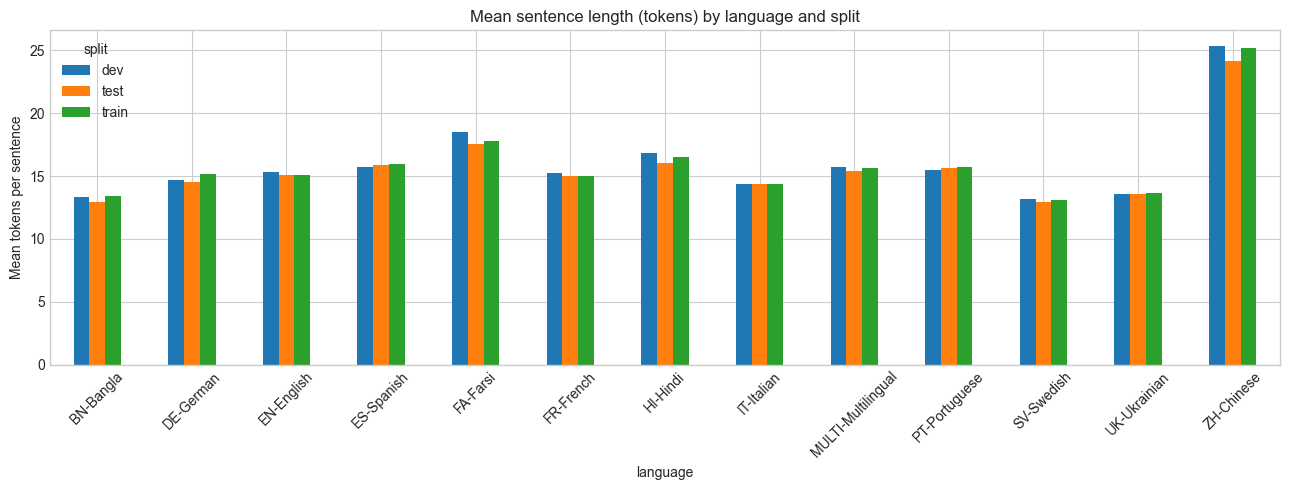

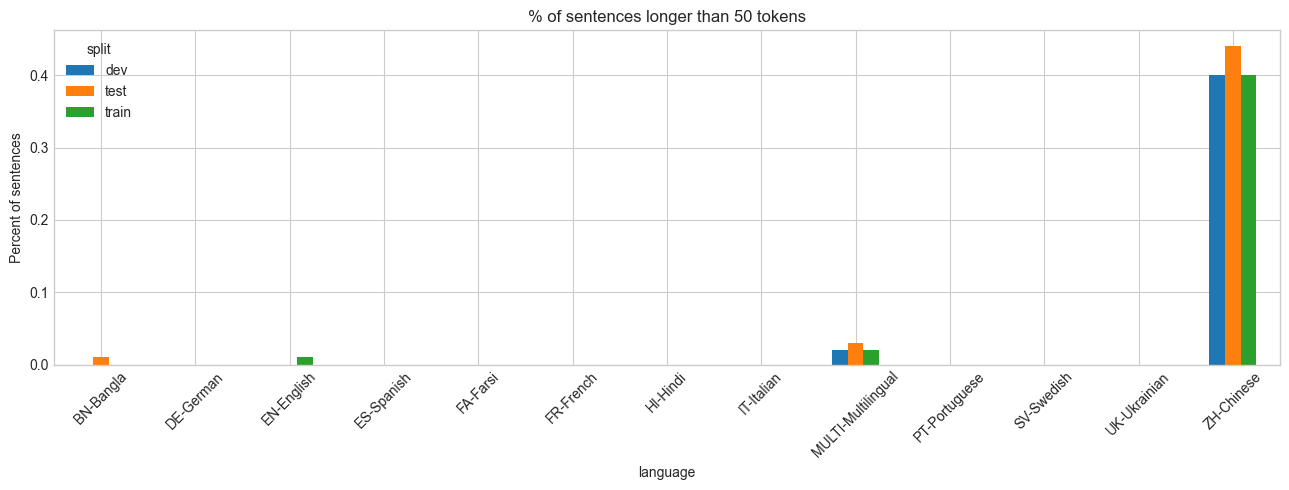

In [18]:
def histogram_quantile(histogram, q):
    total = sum(histogram.values())
    if total == 0:
        return float('nan')
    target = max(1, int((total - 1) * q) + 1)
    cumulative = 0
    for length, count in sorted(histogram.items()):
        cumulative += count
        if cumulative >= target:
            return length

rows = []
for (language, split), stats in sorted(stats_by_group.items()):
    docs = stats['documents']
    if docs == 0:
        continue
    hist = stats['length_hist']
    total_docs = sum(hist.values())
    over_50 = sum(c for l, c in hist.items() if l > 50)
    rows.append({
        'language': language, 'split': split,
        'documents': docs,
        'mean_tokens': round(stats['length_sum'] / docs, 2),
        'median_tokens': histogram_quantile(hist, 0.5),
        'p95_tokens': histogram_quantile(hist, 0.95),
        'p99_tokens': histogram_quantile(hist, 0.99),
        'pct_over_50': round(100 * over_50 / total_docs, 2),
        'max_tokens': max(hist) if hist else 0,
    })

sentence_length_by_lang = pd.DataFrame(rows)
display(sentence_length_by_lang)

pivot_mean = sentence_length_by_lang.pivot(index='language', columns='split', values='mean_tokens')
ax = pivot_mean.plot(kind='bar', figsize=(13, 5))
ax.set_title('Mean sentence length (tokens) by language and split')
ax.set_ylabel('Mean tokens per sentence')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

pivot_over50 = sentence_length_by_lang.pivot(index='language', columns='split', values='pct_over_50')
ax = pivot_over50.plot(kind='bar', figsize=(13, 5))
ax.set_title('% of sentences longer than 50 tokens')
ax.set_ylabel('Percent of sentences')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()


### 3. Label distribution shift across splits (train vs dev vs test)


language        BN-Bangla               DE-German               EN-English  \
split                 dev   test  train       dev   test  train        dev   
entity_type                                                                  
Artist               9.76  10.97   8.86     12.25  16.15  12.49      16.36   
Athlete              3.70   4.35   4.25      5.59   7.75   6.05       6.10   
Facility             3.25   3.57   3.20      2.97   3.86   3.27       4.01   
HumanSettlement     11.83  24.03  11.94      8.09  12.73   8.05       8.41   
MusicalGRP           2.22   1.20   2.30      5.11   2.99   3.61       2.85   
MusicalWork          1.78   0.90   1.97      3.92   3.90   3.96       4.71   
ORG                  4.73   7.95   5.04      5.47   5.87   4.72       6.02   
OtherPER             4.73   4.47   5.12      5.83   7.29   6.73       7.02   
OtherPROD            2.81   2.81   3.06      2.38   2.86   3.26       3.78   
Politician           5.18   5.17   4.80      3.57   4.48   3.89       4.09   
VisualWork           4.14   3.69   3.77      4.52   5.01   4.10       4.71   
WrittenWork          3.85   4.89   4.28      3.33   4.35   3.54       4.17   

language                      ES-Spanish  ... PT-Portuguese SV-Swedish         \
split             test  train        dev  ...         train        dev   test   
entity_type                               ...                                   
Artist           15.10  14.59      13.81  ...         12.70      13.08  12.35   
Athlete           7.31   7.05       5.44  ...          4.75       4.96   4.45   
Facility          4.28   4.14       3.33  ...          3.29       4.10   4.74   
HumanSettlement  10.88  10.28      12.75  ...         13.91      16.46  19.93   
MusicalGRP        3.43   3.24       3.25  ...          3.34       2.80   3.23   
MusicalWork       4.05   3.74       3.74  ...          3.99       2.66   3.52   
ORG               5.93   5.82       5.52  ...          5.08       4.82   5.38   
OtherPER          5.83   6.98       7.47  ...          6.99       6.69   5.97   
OtherPROD         3.13   3.09       3.09  ...          3.46       3.67   3.19   
Politician        4.23   4.13       4.31  ...          4.82       4.39   5.09   
VisualWork        5.21   4.97       3.74  ...          4.68       4.17   4.02   
WrittenWork       4.48   4.22       3.82  ...          3.43       5.18   5.99   

language               UK-Ukrainian               ZH-Chinese                
split            train          dev   test  train        dev   test  train  
entity_type                                                                 
Artist           11.25         8.63   8.96   8.23      10.74  13.19  10.95  
Athlete           4.27         5.46   5.97   5.05       5.05   6.41   5.66  
Facility          4.28         4.14   4.40   3.95       4.14   4.55   3.82  
HumanSettlement  18.05        18.41  18.91  17.47       8.80  15.07   8.98  
MusicalGRP        2.73         2.29   2.53   2.30       3.49   2.55   3.13  
MusicalWork       3.19         2.03   2.34   2.11       2.98   1.75   2.56  
ORG               4.93         4.41   5.32   5.15       4.40   7.18   4.93  
OtherPER          6.66         6.87   5.91   6.67       6.21   5.48   6.15  
OtherPROD         3.15         3.96   4.25   4.16       2.85   3.31   3.18  
Politician        4.61         4.58   5.17   4.79       4.01   4.37   3.94  
VisualWork        3.55         3.61   3.81   3.39       4.66   5.46   4.56  
WrittenWork       5.39         3.96   4.50   4.09       2.98   4.90   3.76  

[12 rows x 39 columns]

,language,entity_type,train_pct,test_pct,shift_pp
0,BN-Bangla,HumanSettlement,11.94,24.03,12.09
5,BN-Bangla,ORG,5.04,7.95,2.91
1,BN-Bangla,Artist,8.86,10.97,2.11
7,BN-Bangla,WrittenWork,4.28,4.89,0.61
8,BN-Bangla,Facility,3.20,3.57,0.38
6,BN-Bangla,Politician,4.80,5.17,0.37
3,BN-Bangla,Athlete,4.25,4.35,0.10
4,BN-Bangla,VisualWork,3.77,3.69,-0.08
10,BN-Bangla,OtherPROD,3.06,2.81,-0.25
2,BN-Bangla,OtherPER,5.12,4.47,-0.65


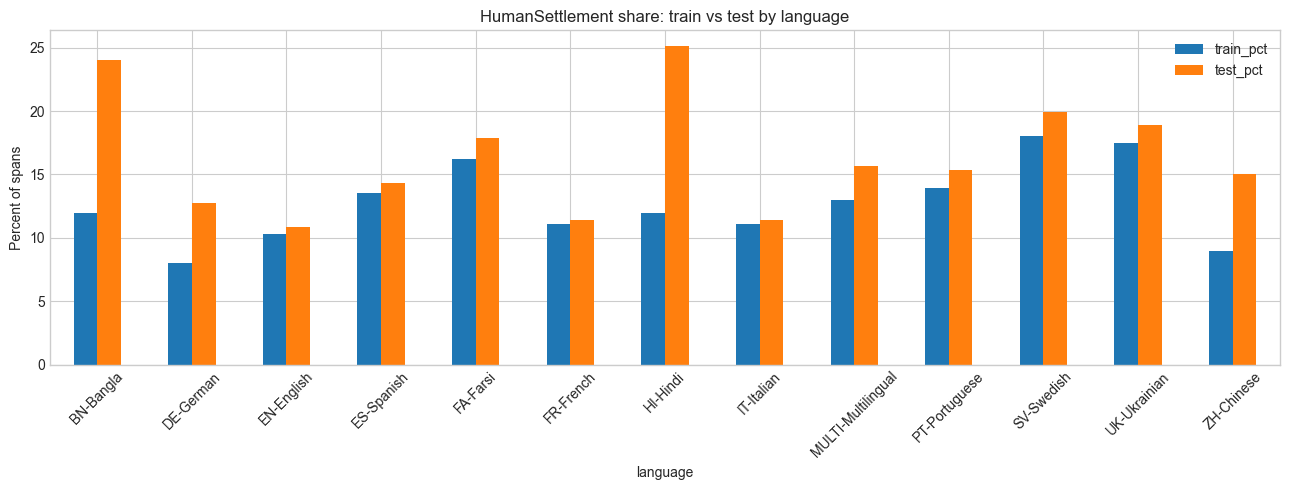

In [19]:
entity_rows = []
for (language, split, entity_type), count in entity_counts.items():
    entity_rows.append({
        'language': language, 'split': split,
        'entity_type': entity_type, 'count': count,
    })
entity_df = pd.DataFrame(entity_rows)

split_totals = entity_df.groupby(['language', 'split'])['count'].sum().reset_index(name='split_total')
entity_df = entity_df.merge(split_totals, on=['language', 'split'])
entity_df['pct'] = 100 * entity_df['count'] / entity_df['split_total']

top_global = (entity_df.groupby('entity_type')['count'].sum()
              .sort_values(ascending=False).head(12).index.tolist())

pivot = entity_df[entity_df['entity_type'].isin(top_global)].pivot_table(
    index='entity_type', columns=['language', 'split'], values='pct', aggfunc='sum').fillna(0)
display(pivot.round(2))

# Train vs test shift in percentage points
shift_rows = []
for lang in sorted(entity_df['language'].unique()):
    sub = entity_df[(entity_df['language'] == lang) & (entity_df['entity_type'].isin(top_global))]
    train_map = sub[sub['split'] == 'train'].set_index('entity_type')['pct']
    test_map = sub[sub['split'] == 'test'].set_index('entity_type')['pct']
    for etype in top_global:
        t = train_map.get(etype, 0.0)
        te = test_map.get(etype, 0.0)
        shift_rows.append({
            'language': lang, 'entity_type': etype,
            'train_pct': round(t, 2), 'test_pct': round(te, 2),
            'shift_pp': round(te - t, 2),
        })
shift_df = pd.DataFrame(shift_rows)
display(shift_df.sort_values(['language', 'shift_pp'], ascending=[True, False]).head(20))

hs = shift_df[shift_df['entity_type'] == 'HumanSettlement']
ax = hs.plot(x='language', y=['train_pct', 'test_pct'], kind='bar', figsize=(13, 5))
ax.set_title('HumanSettlement share: train vs test by language')
ax.set_ylabel('Percent of spans')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()


### 4. Corrupt vs clean documents (test splits)


,language,split,corrupt,documents,tokens,spans,mean_len,spans_per_100_tokens
0,BN-Bangla,dev,missing,507,6772,676,13.36,9.98
1,BN-Bangla,test,missing,19859,256556,25013,12.92,9.75
2,BN-Bangla,train,missing,9708,130181,13223,13.41,10.16
3,DE-German,dev,missing,512,7502,841,14.65,11.21
4,DE-German,test,missing,14260,206861,20406,14.51,9.86
5,DE-German,test,true,5880,85792,8460,14.59,9.86
6,DE-German,test,false,5,65,11,13.00,16.92
7,DE-German,train,missing,9785,148310,15951,15.16,10.76
8,EN-English,dev,missing,871,13323,1296,15.30,9.73
9,EN-English,test,missing,174986,2642571,264583,15.10,10.01


corrupt,false,true
language,,
DE-German,16.92,9.86
EN-English,25.92,10.00
ES-Spanish,20.25,9.05
FR-French,27.42,10.64
IT-Italian,27.95,11.18
MULTI-Multilingual,6.81,9.74
PT-Portuguese,34.46,9.46
SV-Swedish,33.33,12.04
ZH-Chinese,5.24,5.74


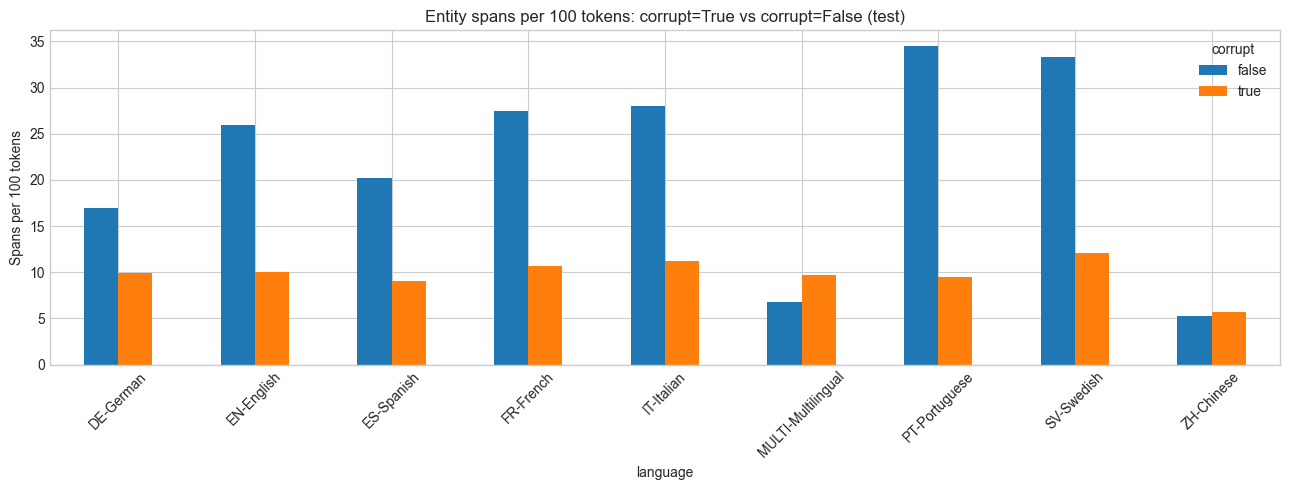

In [20]:
import re
META_RE = re.compile(r'\b(domain|corrupt)=([^\s]+)')
TAG_RE = re.compile(r'^(?:O|[BI]-.+)$')

def _new_corrupt_stats():
    return {'documents': 0, 'tokens': 0, 'spans': 0,
            'length_sum': 0, 'length_hist': Counter()}

corrupt_stats = defaultdict(lambda: defaultdict(_new_corrupt_stats))

def analyze_corrupt_file(path, language, split, stats_container):
    group_key = (language, split)
    stats_by_status = stats_container[group_key]
    doc = {'tokens': 0, 'spans': 0, 'prev_type': None, 'corrupt': None}

    def finish_sentence():
        if doc['tokens'] == 0:
            return
        status = 'true' if doc['corrupt'] is True else (
            'false' if doc['corrupt'] is False else 'missing')
        st = stats_by_status[status]
        st['documents'] += 1
        st['tokens'] += doc['tokens']
        st['spans'] += doc['spans']
        st['length_sum'] += doc['tokens']
        st['length_hist'][doc['tokens']] += 1
        doc.update(tokens=0, spans=0, prev_type=None, corrupt=None)

    with path.open('r', encoding='utf-8-sig', errors='replace') as stream:
        for line in stream:
            line = line.strip()
            if not line:
                finish_sentence()
                continue
            if line.startswith('#'):
                if doc['tokens']:
                    finish_sentence()
                fields = dict(META_RE.findall(line))
                corrupt_value = fields.get('corrupt', '').lower()
                doc['corrupt'] = (corrupt_value == 'true') if corrupt_value in {'true', 'false'} else None
                continue
            columns = line.split()
            if len(columns) != 4 or not TAG_RE.fullmatch(columns[-1]):
                doc['prev_type'] = None
                continue
            tag = columns[-1]
            doc['tokens'] += 1
            if tag == 'O':
                doc['prev_type'] = None
            elif tag.startswith('B-'):
                doc['spans'] += 1
                doc['prev_type'] = tag[2:]
            else:
                etype = tag[2:]
                if doc['prev_type'] != etype:
                    doc['spans'] += 1
                doc['prev_type'] = etype
    finish_sentence()

files = sorted(DATA_ROOT.glob('*/*.conll'))
for file_path in files:
    match = re.search(r'_(train|dev|test)\.conll$', file_path.name, flags=re.IGNORECASE)
    if not match:
        continue
    split = match.group(1).lower()
    analyze_corrupt_file(file_path, file_path.parent.name, split, corrupt_stats)

rows = []
for (language, split), statuses in sorted(corrupt_stats.items()):
    for status, st in statuses.items():
        if st['documents'] == 0:
            continue
        rows.append({
            'language': language, 'split': split, 'corrupt': status,
            'documents': st['documents'], 'tokens': st['tokens'], 'spans': st['spans'],
            'mean_len': round(st['length_sum'] / st['documents'], 2),
            'spans_per_100_tokens': round(100 * st['spans'] / st['tokens'], 2) if st['tokens'] else 0,
        })
corrupt_df = pd.DataFrame(rows)
display(corrupt_df)

test_corrupt = corrupt_df[(corrupt_df['split'] == 'test') & (corrupt_df['corrupt'].isin(['true', 'false']))]
if not test_corrupt.empty:
    pivot = test_corrupt.pivot_table(index='language', columns='corrupt', values='spans_per_100_tokens')
    display(pivot.round(2))
    ax = pivot.plot(kind='bar', figsize=(13, 5))
    ax.set_title('Entity spans per 100 tokens: corrupt=True vs corrupt=False (test)')
    ax.set_ylabel('Spans per 100 tokens')
    ax.tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.show()


### 5. Entity-type coverage by language and long-tail distribution


'Entity-type x language span counts (summed over splits):'

language,BN-Bangla,DE-German,EN-English,ES-Spanish,FA-Farsi,FR-French,HI-Hindi,IT-Italian,MULTI-Multilingual,PT-Portuguese,SV-Swedish,UK-Ukrainian,ZH-Chinese
entity_type,,,,,,,,,,,,,
HumanSettlement,7670,5029,43829,54369,59777,48560,7442,48511,116851,55847,76810,63684,5654
Artist,3982,6760,60959,51331,55306,61025,2942,72086,105465,52394,47656,30152,5443
ORG,2686,2495,23972,19847,19834,22071,2587,15764,43180,19695,20747,17964,2793
Politician,1964,1945,17093,19067,21113,20704,1847,17321,38078,19627,19618,17420,1854
OtherPER,1826,3228,23896,24374,22542,26447,1416,22078,48141,23120,23341,20171,2518
WrittenWork,1816,1847,18039,15964,14443,38270,1402,13198,37414,14514,23082,15137,1967
Athlete,1674,3251,29508,21816,13425,24511,1815,40907,46283,19496,17224,20000,2696
VisualWork,1449,2140,21005,16209,26711,30059,1262,40946,43283,19555,15480,12809,2260
Facility,1339,1662,17290,14306,12152,18385,1329,16538,31001,13193,18250,14801,1887


'Percent of tokens in entity spans of each type, by language:'

language,BN-Bangla,DE-German,EN-English,ES-Spanish,FA-Farsi,FR-French,HI-Hindi,IT-Italian,MULTI-Multilingual,PT-Portuguese,SV-Swedish,UK-Ukrainian,ZH-Chinese
entity_type,,,,,,,,,,,,,
HumanSettlement,1.9491,1.1212,1.0849,1.2938,1.4387,1.2129,1.6060,1.2752,1.3995,1.4437,2.3828,1.8332,0.7559
Artist,1.0119,1.5071,1.5089,1.2215,1.3311,1.5242,0.6349,1.8949,1.2631,1.3544,1.4784,0.8679,0.7276
ORG,0.6826,0.5563,0.5934,0.4723,0.4774,0.5513,0.5583,0.4144,0.5172,0.5091,0.6436,0.5171,0.3734
Politician,0.4991,0.4336,0.4231,0.4537,0.5082,0.5171,0.3986,0.4553,0.4561,0.5074,0.6086,0.5014,0.2479
OtherPER,0.4640,0.7197,0.5915,0.5800,0.5425,0.6606,0.3056,0.5803,0.5766,0.5977,0.7241,0.5806,0.3366
WrittenWork,0.4615,0.4118,0.4465,0.3799,0.3476,0.9559,0.3026,0.3469,0.4481,0.3752,0.7161,0.4357,0.2630
Athlete,0.4254,0.7248,0.7304,0.5192,0.3231,0.6122,0.3917,1.0753,0.5543,0.5040,0.5343,0.5757,0.3604
VisualWork,0.3682,0.4771,0.5199,0.3857,0.6429,0.7508,0.2723,1.0763,0.5184,0.5055,0.4802,0.3687,0.3021
Facility,0.3403,0.3705,0.4280,0.3404,0.2925,0.4592,0.2868,0.4347,0.3713,0.3410,0.5662,0.4260,0.2523


,entity_type,count,cumulative_pct
entity_type,,,
HumanSettlement,HumanSettlement,594033,14.77
Artist,Artist,555501,28.57
OtherPER,OtherPER,243098,34.61
Athlete,Athlete,242606,40.64
VisualWork,VisualWork,233168,46.44
ORG,ORG,213635,51.75
Politician,Politician,197651,56.66
WrittenWork,WrittenWork,197093,61.56
Facility,Facility,162133,65.59


Entity types needed to cover 80% of all spans: 13
Total entity types observed: 33


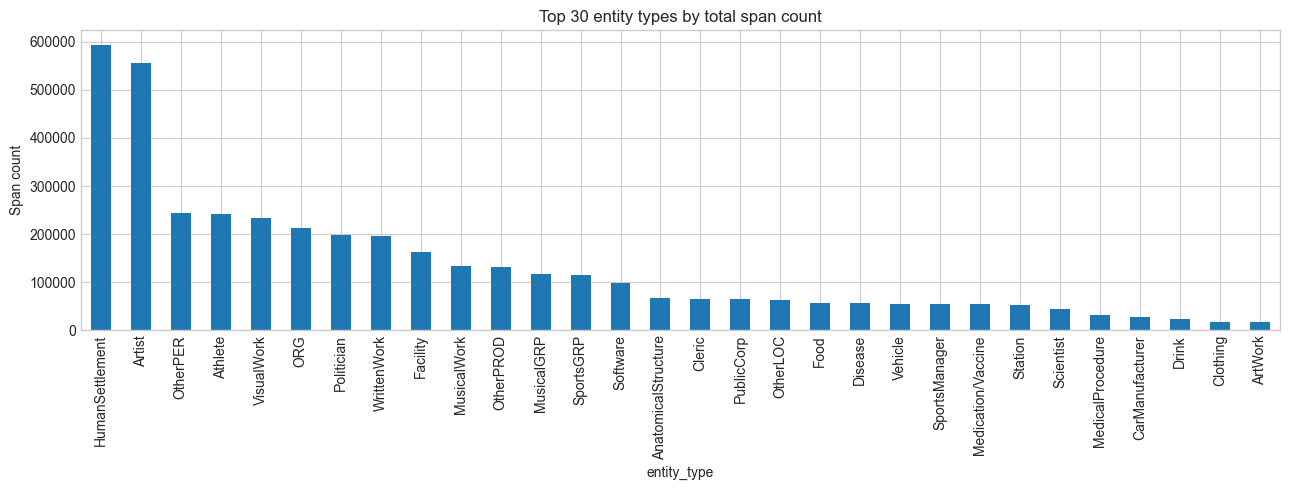

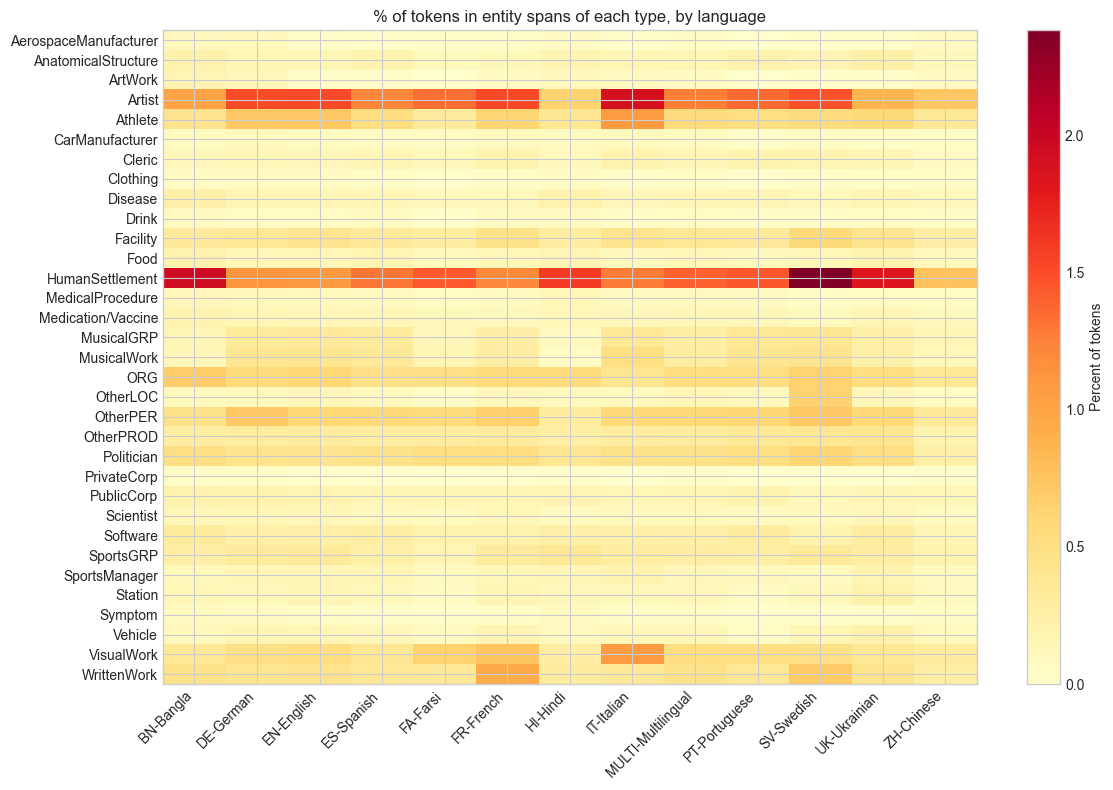

In [23]:
from collections import defaultdict

# Total tokens per language (summed over splits) from the existing streaming stats
lang_tokens = defaultdict(int)
for (language, split), stats in stats_by_group.items():
    lang_tokens[language] += stats['tokens']

# Span counts per entity type per language (summed over splits)
pivot_counts = entity_df.pivot_table(index='entity_type', columns='language', values='count', aggfunc='sum').fillna(0).astype(int)

# Percent of tokens that are part of an entity span of this type, per language
pivot_pct = pivot_counts.copy().astype(float)
for lang in pivot_pct.columns:
    total = lang_tokens.get(lang, 0)
    pivot_pct[lang] = 100 * pivot_pct[lang] / total if total else 0.0

display('Entity-type x language span counts (summed over splits):')
display(pivot_counts.sort_values(by=pivot_counts.columns.tolist(), ascending=False).head(20))

display('Percent of tokens in entity spans of each type, by language:')
display(pivot_pct.round(4).sort_values(by=pivot_pct.columns.tolist(), ascending=False))

# Long-tail (based on span counts)
type_totals = pivot_counts.sum(axis=1).sort_values(ascending=False)
cumulative_pct = 100 * type_totals.cumsum() / type_totals.sum()
longtail = pd.DataFrame({
    'entity_type': type_totals.index,
    'count': type_totals.values,
    'cumulative_pct': cumulative_pct.round(2),
})
display(longtail.head(25))

n_80 = int((cumulative_pct <= 80).sum())
print(f'Entity types needed to cover 80% of all spans: {n_80}')
print(f'Total entity types observed: {len(type_totals)}')

ax = longtail.head(30).plot(x='entity_type', y='count', kind='bar', figsize=(13, 5), legend=False)
ax.set_title('Top 30 entity types by total span count')
ax.set_ylabel('Span count')
ax.tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.show()

# Heatmap: percent of tokens per entity type per language
fig, ax = plt.subplots(figsize=(12, 8))
im = ax.imshow(pivot_pct.values, aspect='auto', cmap='YlOrRd', vmin=0)
ax.set_xticks(range(len(pivot_pct.columns)))
ax.set_xticklabels(pivot_pct.columns, rotation=45, ha='right')
ax.set_yticks(range(len(pivot_pct.index)))
ax.set_yticklabels(pivot_pct.index)
ax.set_title('% of tokens in entity spans of each type, by language')
plt.colorbar(im, ax=ax, label='Percent of tokens')
plt.tight_layout()
plt.show()


### 6. Vocabulary, OOV, and casing diagnostics


,language,split,tokens,types,ttr,avg_chars_per_token
0,BN-Bangla,dev,6772,3282,0.4846,5.49
1,BN-Bangla,test,256556,33989,0.1325,5.46
2,BN-Bangla,train,130181,22280,0.1711,5.48
3,DE-German,dev,7502,3455,0.4605,5.27
4,DE-German,test,292718,48199,0.1647,5.18
5,DE-German,train,148310,29933,0.2018,5.25
6,EN-English,dev,13323,4733,0.3553,4.47
7,EN-English,test,3773671,235431,0.0624,4.46
8,EN-English,train,253011,34140,0.1349,4.48
9,ES-Spanish,dev,13462,4873,0.3620,4.57


OOV types in dev/test relative to train (per language):


,language,split,split_types,oov_types,oov_type_pct
0,BN-Bangla,dev,3282,645,19.65
1,BN-Bangla,test,33989,19970,58.75
2,DE-German,dev,3455,1012,29.29
3,DE-German,test,48199,32582,67.60
4,EN-English,dev,4733,1093,23.09
5,EN-English,test,235431,207740,88.24
6,ES-Spanish,dev,4873,1144,23.48
7,ES-Spanish,test,227309,196858,86.60
8,FA-Farsi,dev,4947,956,19.32
9,FA-Farsi,test,129984,103992,80.00


,language,split,title_pct,upper_pct,lower_pct,other_pct
0,DE-German,dev,0.0,0.0,100.0,0.0
1,DE-German,test,0.0,0.0,100.0,0.0
2,DE-German,train,0.0,0.0,100.0,0.0
3,EN-English,dev,0.0,0.0,100.0,0.0
4,EN-English,test,0.0,0.0,100.0,0.0
5,EN-English,train,0.0,0.0,100.0,0.0
6,ES-Spanish,dev,0.0,0.0,100.0,0.0
7,ES-Spanish,test,0.0,0.0,100.0,0.0
8,ES-Spanish,train,0.0,0.0,100.0,0.0
9,FR-French,dev,0.0,0.0,100.0,0.0


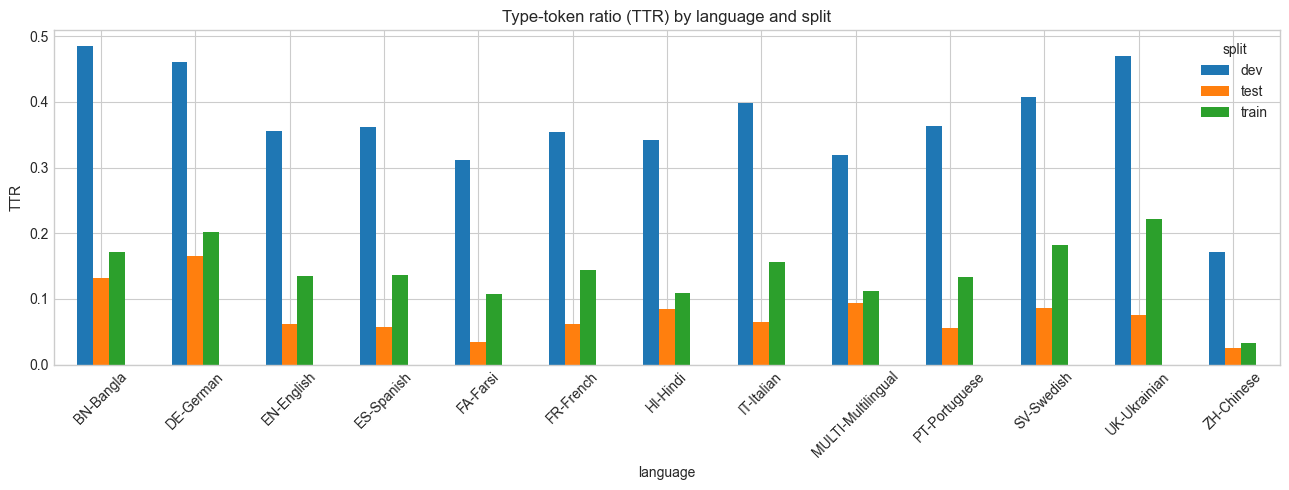

In [22]:
TAG_RE = re.compile(r'^(?:O|[BI]-.+)$')

vocab = defaultdict(set)
token_counts = defaultdict(int)
char_len_sum = defaultdict(int)
casing = defaultdict(Counter)

def is_latin_script(s):
    return any(('a' <= ch <= 'z') or ('A' <= ch <= 'Z') for ch in s)

def analyze_vocab_file(path, language, split):
    group_key = (language, split)
    with path.open('r', encoding='utf-8-sig', errors='replace') as stream:
        for line in stream:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            columns = line.split()
            if len(columns) != 4 or not TAG_RE.fullmatch(columns[-1]):
                continue
            token = columns[0]
            vocab[group_key].add(token)
            token_counts[group_key] += 1
            char_len_sum[group_key] += len(token)
            if is_latin_script(token):
                if token.istitle():
                    casing[group_key]['title'] += 1
                elif token.isupper():
                    casing[group_key]['upper'] += 1
                elif token.islower():
                    casing[group_key]['lower'] += 1
                else:
                    casing[group_key]['other'] += 1

files = sorted(DATA_ROOT.glob('*/*.conll'))
for file_path in files:
    match = re.search(r'_(train|dev|test)\.conll$', file_path.name, flags=re.IGNORECASE)
    if not match:
        continue
    split = match.group(1).lower()
    analyze_vocab_file(file_path, file_path.parent.name, split)

rows = []
for (language, split) in sorted(vocab):
    n_tokens = token_counts[(language, split)]
    n_types = len(vocab[(language, split)])
    rows.append({
        'language': language, 'split': split,
        'tokens': n_tokens,
        'types': n_types,
        'ttr': round(n_types / n_tokens, 4) if n_tokens else 0,
        'avg_chars_per_token': round(char_len_sum[(language, split)] / n_tokens, 2) if n_tokens else 0,
    })
vocab_df = pd.DataFrame(rows)
display(vocab_df)

print('OOV types in dev/test relative to train (per language):')
oov_rows = []
for language in sorted({lang for lang, _ in vocab}):
    train_vocab = vocab.get((language, 'train'), set())
    for split in ('dev', 'test'):
        if (language, split) not in vocab:
            continue
        split_vocab = vocab[(language, split)]
        oov = split_vocab - train_vocab
        oov_rows.append({
            'language': language, 'split': split,
            'split_types': len(split_vocab),
            'oov_types': len(oov),
            'oov_type_pct': round(100 * len(oov) / len(split_vocab), 2) if split_vocab else 0,
        })
oov_df = pd.DataFrame(oov_rows)
display(oov_df)

latin_langs = ['EN-English', 'DE-German', 'ES-Spanish', 'FR-French', 'IT-Italian', 'PT-Portuguese']
casing_rows = []
for (language, split), ctr in casing.items():
    if language not in latin_langs:
        continue
    total = sum(ctr.values())
    if total == 0:
        continue
    casing_rows.append({
        'language': language, 'split': split,
        'title_pct': round(100 * ctr.get('title', 0) / total, 1),
        'upper_pct': round(100 * ctr.get('upper', 0) / total, 1),
        'lower_pct': round(100 * ctr.get('lower', 0) / total, 1),
        'other_pct': round(100 * ctr.get('other', 0) / total, 1),
    })
casing_df = pd.DataFrame(casing_rows)
display(casing_df)

pivot_ttr = vocab_df.pivot(index='language', columns='split', values='ttr')
ax = pivot_ttr.plot(kind='bar', figsize=(13, 5))
ax.set_title('Type-token ratio (TTR) by language and split')
ax.set_ylabel('TTR')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()
